In [20]:
from PIL import Image, ImageDraw

# Imagen 120x120, fondo beige
img = Image.new("RGB", (120, 120), (240, 230, 200))
draw = ImageDraw.Draw(img)

draw.rectangle([10, 70, 60, 110], fill=(200, 30, 30))   # figura 1: rectángulo rojo
draw.ellipse([70, 15, 110, 55], fill=(30, 80, 200))     # figura 2: círculo azul

print(img.size, img.mode)
img.save("mi_imagen.png")

(120, 120) RGB


In [16]:
img = Image.open("mi_imagen.png")
print(img.format)  # PNG

# Coordenadas que usé (anótalas, las necesitas en la Tarea 3)
print("Fondo     (5, 5)   :", img.getpixel((5, 5)))
print("Rectángulo (30, 90):", img.getpixel((30, 90)))
print("Círculo   (90, 35) :", img.getpixel((90, 35)))

PNG
Fondo     (5, 5)   : (240, 230, 200)
Rectángulo (30, 90): (200, 30, 30)
Círculo   (90, 35) : (30, 80, 200)


In [17]:
gris = img.convert("L")
rotada = img.rotate(90, expand=True)
mitad = img.resize((img.width // 2, img.height // 2))
volteada = img.transpose(Image.Transpose.FLIP_TOP_BOTTOM)

print("convert('L'):", gris.size)
print("rotate(90)  :", rotada.size)
print("resize      :", mitad.size)
print("flip vert.  :", volteada.size)

convert('L'): (120, 120)
rotate(90)  : (120, 120)
resize      : (60, 60)
flip vert.  : (120, 120)


In [18]:
from PIL import Image, ImageEnhance, ImageFilter

img = Image.open("mi_imagen.png")
enh = ImageEnhance.Brightness(img)

oscura = enh.enhance(0.5)   # factor < 1.0
clara  = enh.enhance(2.5)   # factor > 2.0

p = (30, 90)  # píxel del rectángulo rojo (200, 30, 30)
print("Antes  :", img.getpixel(p))
print("Después:", clara.getpixel(p))

Antes  : (200, 30, 30)
Después: (255, 75, 75)


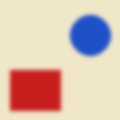

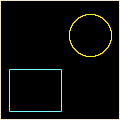

In [19]:
blur = img.filter(ImageFilter.GaussianBlur(radius=2))
bordes = img.filter(ImageFilter.FIND_EDGES)

blur.save("mi_imagen_blur.png")
bordes.save("mi_imagen_bordes.png")
display(blur)
display(bordes)

In [21]:
import numpy as np
from skimage import color, filters

arr = np.array(img)
print(arr.shape, arr.dtype)        # (120, 120, 3) uint8

gris_sk = color.rgb2gray(arr)      # float entre 0 y 1
gris_pil = img.convert("L")

q = (5, 5)  # píxel de fondo
# Ojo: en NumPy el orden es [fila, columna] = [y, x]
print("skimage x255:", gris_sk[q[1], q[0]] * 255)
print("Pillow L    :", gris_pil.getpixel(q))

(120, 120, 3) uint8
skimage x255: 229.962
Pillow L    : 230


In [22]:
umbral = filters.threshold_otsu(gris_sk)
binaria = gris_sk > umbral

print("Umbral Otsu:", umbral)
print("Proporción True:", binaria.mean())

Umbral Otsu: 0.3057442478553921
Proporción True: 0.8547916666666666


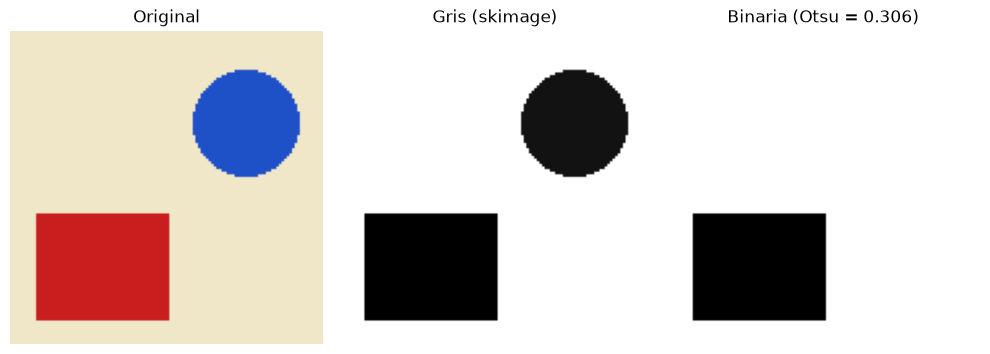

In [23]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 3, figsize=(10, 4))

axs[0].imshow(img)
axs[0].set_title("Original")

axs[1].imshow(gris_sk, cmap="gray")
axs[1].set_title("Gris (skimage)")

axs[2].imshow(binaria, cmap="gray")
axs[2].set_title(f"Binaria (Otsu = {umbral:.3f})")

for ax in axs:
    ax.axis("off")

plt.tight_layout()
plt.show()